In [1]:

import pandas as pd
from io import StringIO

data = """Area_sqft,Bedrooms,Bathrooms,House_Age,SalePrice
1000,2,1,5,120000
1200,2,2,4,145000
1500,3,2,6,180000
1800,3,2,3,220000
2000,3,3,2,260000
2200,4,3,5,285000
2500,4,3,4,320000
2800,4,3,3,350000
3000,4,4,2,390000
1100,2,1,10,110000
1400,3,2,8,155000
1600,3,2,7,175000
1900,3,3,6,225000
2100,4,2,8,250000
2400,4,3,7,295000
2700,4,3,6,330000
2900,5,4,4,375000
3200,5,4,3,420000
"""

df = pd.read_csv(StringIO(data))

print("Dataset created successfully!")
display(df)


Dataset created successfully!


,Area_sqft,Bedrooms,Bathrooms,House_Age,SalePrice
0,1000,2,1,5,120000
1,1200,2,2,4,145000
2,1500,3,2,6,180000
3,1800,3,2,3,220000
4,2000,3,3,2,260000
5,2200,4,3,5,285000
6,2500,4,3,4,320000
7,2800,4,3,3,350000
8,3000,4,4,2,390000
9,1100,2,1,10,110000


In [3]:



print("Total Houses:", len(df))
print("\nAverage House Price:", df["SalePrice"].mean())
print("\nAverage House Area:", df["Area_sqft"].mean())

print("\nDataset Columns:")
print(df.columns.tolist())


Total Houses: 18

Average House Price: 255833.33333333334

Average House Area: 2072.222222222222

Dataset Columns:
['Area_sqft', 'Bedrooms', 'Bathrooms', 'House_Age', 'SalePrice']


In [5]:



df_display = df.copy()

df_display["SalePrice"] = df_display["SalePrice"].apply(
    lambda price: f"${price:,.0f}"
)

display(df_display)


average_price = df["SalePrice"].mean()

print(f"Average House Price: ${average_price:,.2f}")


,Area_sqft,Bedrooms,Bathrooms,House_Age,SalePrice
0,1000,2,1,5,"$120,000"
1,1200,2,2,4,"$145,000"
2,1500,3,2,6,"$180,000"
3,1800,3,2,3,"$220,000"
4,2000,3,3,2,"$260,000"
5,2200,4,3,5,"$285,000"
6,2500,4,3,4,"$320,000"
7,2800,4,3,3,"$350,000"
8,3000,4,4,2,"$390,000"
9,1100,2,1,10,"$110,000"


Average House Price: $255,833.33


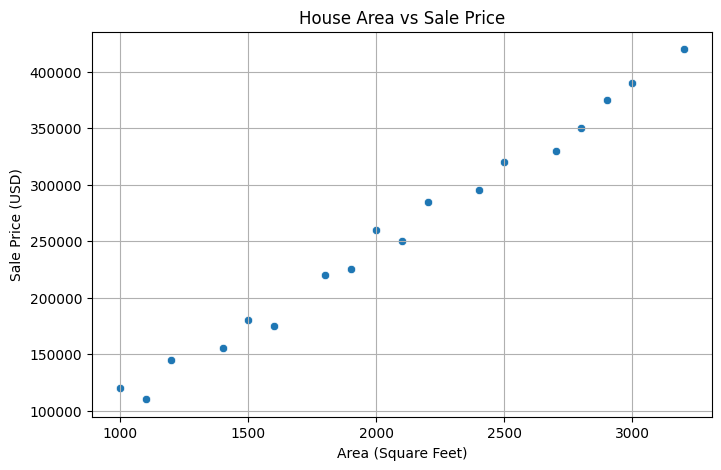

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Area_sqft", y="SalePrice")

plt.title("House Area vs Sale Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("Sale Price (USD)")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(True)
plt.show()

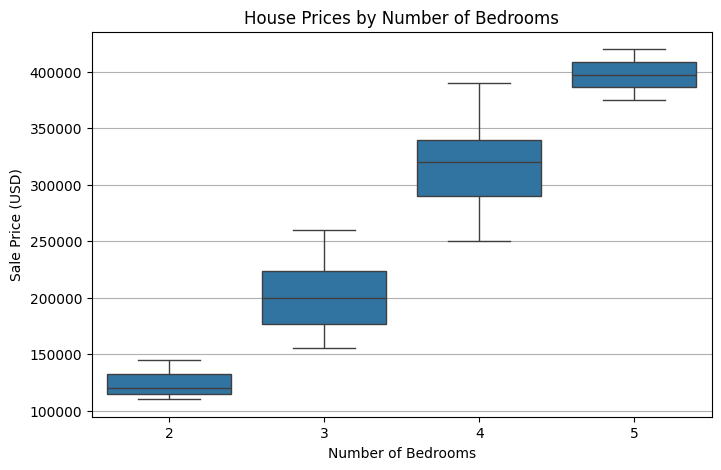

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Bedrooms", y="SalePrice")

plt.title("House Prices by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Sale Price (USD)")
plt.ticklabel_format(style="plain", axis="y")
plt.grid(axis="y")
plt.show()

In [11]:

X = df[["Area_sqft", "Bedrooms", "Bathrooms", "House_Age"]]


y = df["SalePrice"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures:")
display(X.head())

print("\nTarget:")
display(y.head())


Features shape: (18, 4)
Target shape: (18,)

Features:


,Area_sqft,Bedrooms,Bathrooms,House_Age
0,1000,2,1,5
1,1200,2,2,4
2,1500,3,2,6
3,1800,3,2,3
4,2000,3,3,2



Target:


,SalePrice
0,120000
1,145000
2,180000
3,220000
4,260000


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (14, 4)
Testing data: (4, 4)


In [16]:
from sklearn.linear_model import LinearRegression


model = LinearRegression()


model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [18]:

y_pred = model.predict(X_test)


comparison = pd.DataFrame({
    "Actual Price (USD)": y_test.values,
    "Predicted Price (USD)": y_pred.round(2)
})

display(comparison)

,Actual Price (USD),Predicted Price (USD)
0,120000,107678.67
1,145000,139797.63
2,390000,387293.71
3,285000,275988.32


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: ${mae:,.2f}")
print(f"Root Mean Squared Error: ${rmse:,.2f}")
print(f"R2 Score: {r2:.4f}")


Mean Absolute Error: $7,310.42
Root Mean Squared Error: $8,176.40
R2 Score: 0.9944


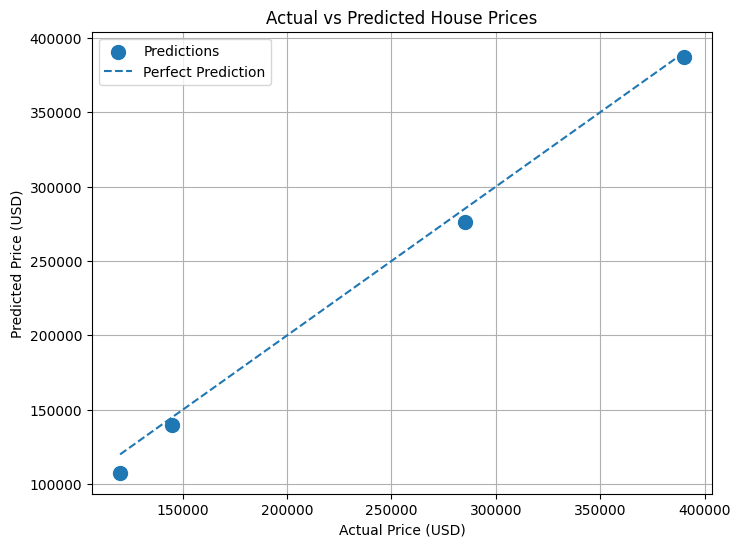

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, s=100, label="Predictions")


plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.legend()
plt.grid(True)

plt.savefig("actual_vs_predicted.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
from google.colab import files

files.download("actual_vs_predicted.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>